# AgriVision AI — PlantVillage Exploratory Data Analysis

## Objective

This notebook performs exploratory data analysis on the PlantVillage
dataset used by AgriVision AI for plant disease classification.

The analysis focuses on:

- Dataset size and structure
- Crop and disease distribution
- Class imbalance
- Image properties
- Sample visualization
- Dataset quality
- Potential issues that may affect model training

The goal is to understand the dataset before building machine
learning models.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
PROJECT_ROOT = Path.cwd().parent

METADATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "plantvillage"
    / "metadata.csv"
)

df = pd.read_csv(METADATA_PATH)

print(f"Dataset loaded: {len(df):,} images")

Dataset loaded: 54,304 images


## 1. Dataset Overview

We first inspect the structure of the processed metadata and
verify the number of observations, variables, and classes.

In [3]:
print("Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Shape:
(54304, 5)

Columns:
['image_path', 'class_id', 'class_name', 'crop', 'condition']

Data types:
image_path      str
class_id      int64
class_name      str
crop            str
condition       str
dtype: object


In [4]:
df.head()

,image_path,class_id,class_name,crop,condition
0,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab
1,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab
2,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab
3,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab
4,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 54304 entries, 0 to 54303
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   image_path  54304 non-null  str  
 1   class_id    54304 non-null  int64
 2   class_name  54304 non-null  str  
 3   crop        54304 non-null  str  
 4   condition   54304 non-null  str  
dtypes: int64(1), str(4)
memory usage: 10.6 MB


In [6]:
df['class_name'].unique()

<ArrowStringArray>
[                                'Apple___Apple_scab',
                                  'Apple___Black_rot',
                           'Apple___Cedar_apple_rust',
                                    'Apple___healthy',
                                'Blueberry___healthy',
           'Cherry_(including_sour)___Powdery_mildew',
                  'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
                        'Corn_(maize)___Common_rust_',
                'Corn_(maize)___Northern_Leaf_Blight',
                             'Corn_(maize)___healthy',
                                  'Grape___Black_rot',
                       'Grape___Esca_(Black_Measles)',
         'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
                                    'Grape___healthy',
           'Orange___Haunglongbing_(Citrus_greening)',
                             'Peach___Bacterial_spot',
                                    'Peach___h

In [7]:
print("Total images:", len(df))
print("Total classes:", df["class_name"].nunique())
print("Total crops:", df["crop"].nunique())

Total images: 54304
Total classes: 38
Total crops: 14


In [8]:
print("\nCrops:")
print(
    sorted(df["crop"].unique())
)


Crops:
['Apple', 'Blueberry', 'Cherry_(including_sour)', 'Corn_(maize)', 'Grape', 'Orange', 'Peach', 'Pepper,_bell', 'Potato', 'Raspberry', 'Soybean', 'Squash', 'Strawberry', 'Tomato']


## 2. Data Quality

Before analyzing the images, we check the metadata for missing
values and duplicate records.

In [9]:
missing_values = df.isnull().sum()

print(missing_values)

image_path    0
class_id      0
class_name    0
crop          0
condition     0
dtype: int64


In [10]:
print("total missing values:", missing_values.sum())

total missing values: 0


In [11]:
print("duplicate rows:", df.duplicated().sum())

duplicate rows: 0


## 3. Class Distribution

PlantVillage contains multiple crop-disease combinations.

Understanding the number of samples per class is important because
strong class imbalance can affect model performance.

In [12]:
class_counts = df["class_name"].value_counts().sort_values(ascending=False)
class_counts.head(10)

class_name
Orange___Haunglongbing_(Citrus_greening)         5507
Tomato___Tomato_Yellow_Leaf_Curl_Virus           5357
Soybean___healthy                                5090
Peach___Bacterial_spot                           2297
Tomato___Bacterial_spot                          2127
Tomato___Late_blight                             1909
Squash___Powdery_mildew                          1835
Tomato___Septoria_leaf_spot                      1771
Tomato___Spider_mites Two-spotted_spider_mite    1676
Apple___healthy                                  1645
Name: count, dtype: int64

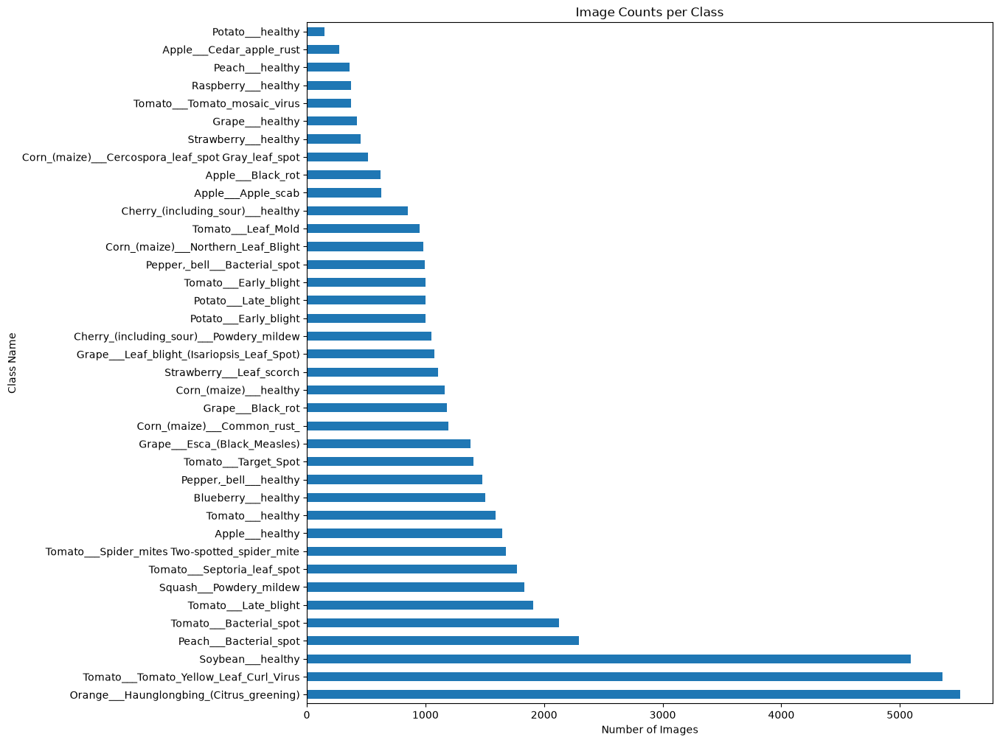

In [13]:
plt.figure(figsize=(12, 12))
class_counts.plot(kind="barh")

plt.title("Image Counts per Class")
plt.xlabel("Number of Images")
plt.ylabel("Class Name")

plt.show()

In [14]:
print("Largest Class count:", class_counts.max())
print("Smallest Class count:", class_counts.min())
print("Mean Class count:", class_counts.mean())
print("Median Class count:", class_counts.median())
print("Ratio of largest to smallest class count:", round((class_counts.max() / class_counts.min()),2))

Largest Class count: 5507
Smallest Class count: 152
Mean Class count: 1429.0526315789473
Median Class count: 1092.5
Ratio of largest to smallest class count: 36.23


In [15]:
class_stats = pd.DataFrame({
    "class_name": class_counts.index,
    "crop_type": df.groupby("class_name")["crop"].first().reindex(class_counts.index).values,
    "image_count": class_counts.values,
    "percentage": (class_counts.values / len(df)) * 100
})

class_stats.head(10)

,class_name,crop_type,image_count,percentage
0,Orange___Haunglongbing_(Citrus_greening),Orange,5507,10.141058
1,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato,5357,9.864835
2,Soybean___healthy,Soybean,5090,9.373159
3,Peach___Bacterial_spot,Peach,2297,4.229891
4,Tomato___Bacterial_spot,Tomato,2127,3.916839
5,Tomato___Late_blight,Tomato,1909,3.515395
6,Squash___Powdery_mildew,Squash,1835,3.379125
7,Tomato___Septoria_leaf_spot,Tomato,1771,3.261270
8,Tomato___Spider_mites Two-spotted_spider_mite,Tomato,1676,3.086329
9,Apple___healthy,Apple,1645,3.029243


## 4. Crop Distribution

The dataset contains multiple crop species. We examine how many
images are available for each crop.

In [16]:
crop_counts = class_stats.groupby("crop_type")["image_count"].sum().sort_values(ascending=False)
crop_counts

crop_type
Tomato                     18160
Orange                      5507
Soybean                     5090
Grape                       4062
Corn_(maize)                3852
Apple                       3171
Peach                       2657
Pepper,_bell                2474
Potato                      2152
Cherry_(including_sour)     1906
Squash                      1835
Strawberry                  1565
Blueberry                   1502
Raspberry                    371
Name: image_count, dtype: int64

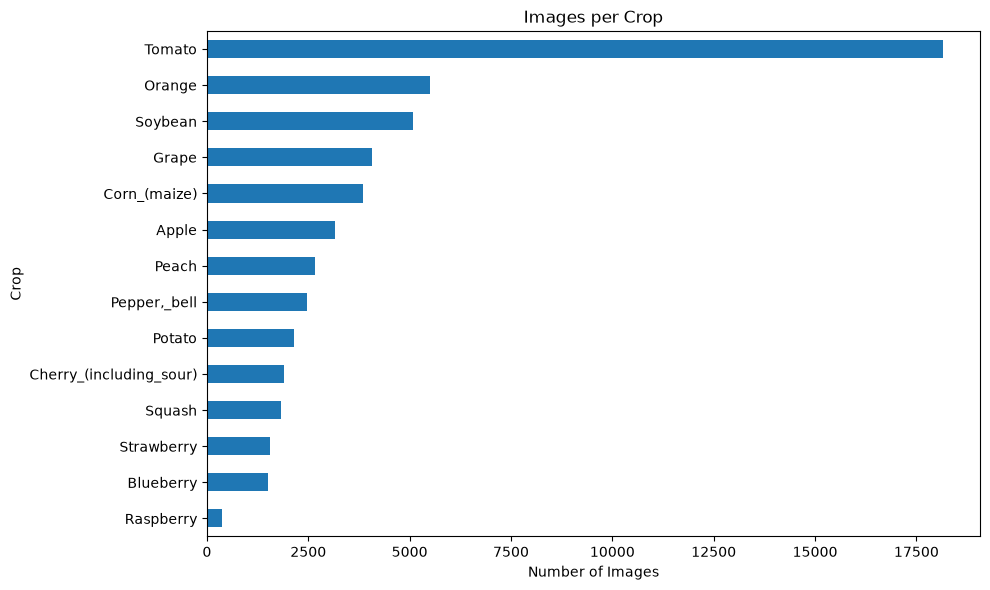

In [17]:
plt.figure(figsize=(10, 6))

crop_counts.sort_values().plot(
    kind="barh"
)

plt.title("Images per Crop")
plt.xlabel("Number of Images")
plt.ylabel("Crop")

plt.tight_layout()
plt.show()

In [18]:
df["is_healthy"] = (
    df["condition"]
    .str.lower()
    .eq("healthy")
)
df.head()

,image_path,class_id,class_name,crop,condition,is_healthy
0,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab,False
1,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab,False
2,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab,False
3,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab,False
4,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab,False


In [19]:
healthy_counts = df["is_healthy"].map({True: "Healthy", False: "Diseased"}).value_counts()
healthy_counts

is_healthy
Diseased    39221
Healthy     15083
Name: count, dtype: int64

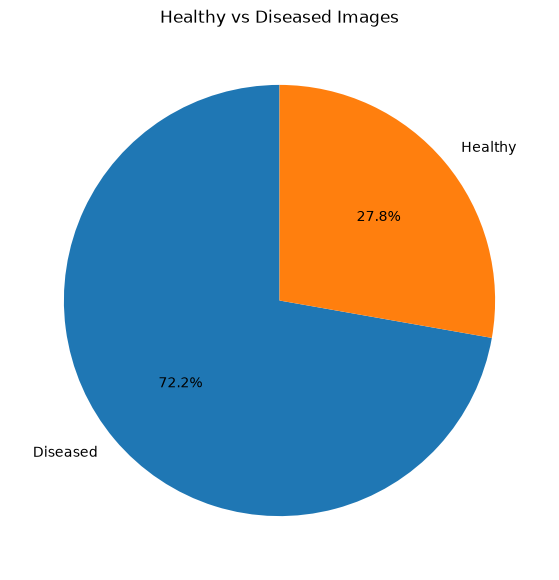

In [20]:
plt.figure(figsize=(7, 7))

plt.pie(
    healthy_counts.values,
    labels=healthy_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Healthy vs Diseased Images")

plt.show()

## 5. Image Visualization

Visual inspection helps identify:

- Background variation
- Lighting differences
- Leaf orientation
- Image quality
- Visible disease characteristics
- Potential dataset artifacts

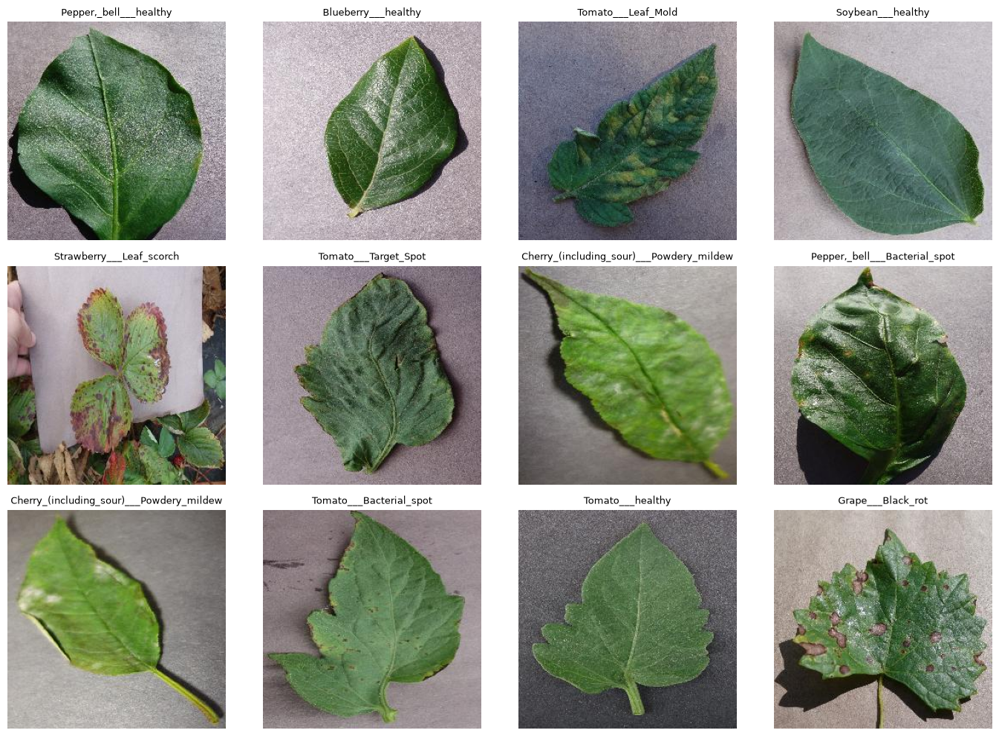

In [21]:
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(df),
    size=12,
    replace=False
)

fig, axes = plt.subplots(
    3,
    4,
    figsize=(14, 10)
)

for ax, index in zip(
    axes.flat,
    sample_indices
):

    row = df.iloc[index]

    image_path = (
        PROJECT_ROOT
        / row["image_path"]
    )

    image = Image.open(image_path)

    ax.imshow(image)

    ax.set_title(
        row["class_name"],
        fontsize=9
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

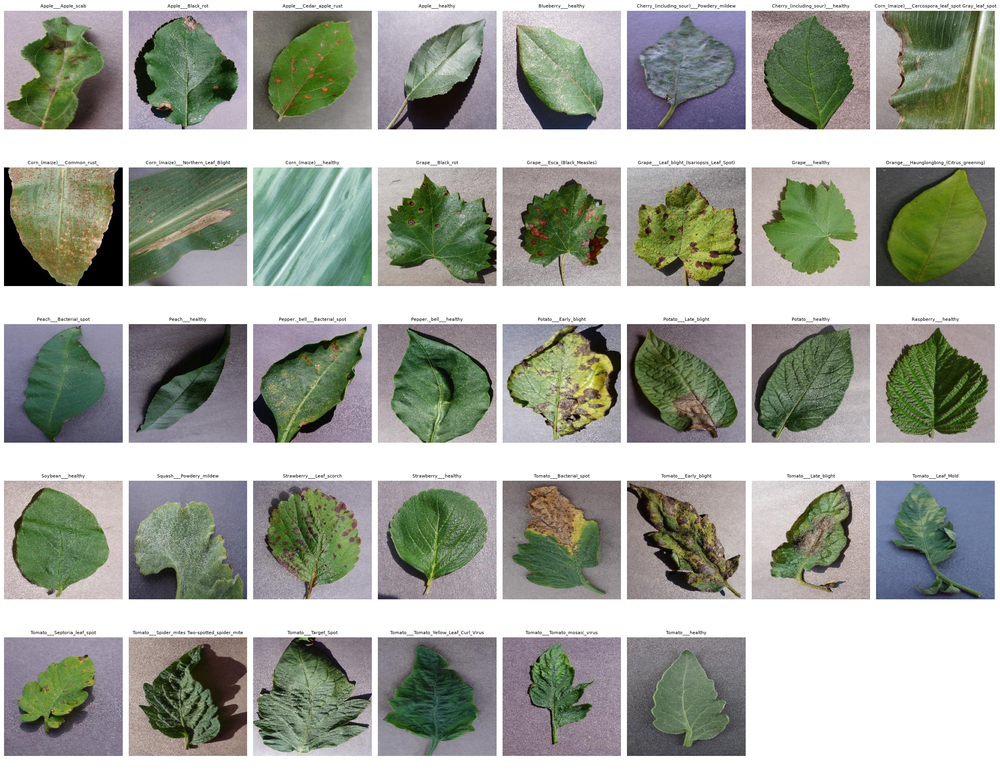

In [22]:
classes = sorted(
    df["class_name"].unique()
)

fig, axes = plt.subplots(
    5,
    8,
    figsize=(25, 20)
)

for ax, class_name in zip(
    axes.flat,
    classes
):

    row = df[
        df["class_name"] == class_name
    ].sample(
        n=1,
        random_state=42
    ).iloc[0]

    image_path = (
        PROJECT_ROOT
        / row["image_path"]
    )

    image = Image.open(image_path)

    ax.imshow(image)

    ax.set_title(
        class_name,
        fontsize=8
    )

    ax.axis("off")

# Hide unused axes
for ax in axes.flat[len(classes):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
sample_size = min(
    5000,
    len(df)
)

sample_df = df.sample(
    sample_size,
    random_state=42
)

widths = []
heights = []

for _, row in sample_df.iterrows():

    image_path = (
        PROJECT_ROOT
        / row["image_path"]
    )

    with Image.open(image_path) as image:

        width, height = image.size

        widths.append(width)
        heights.append(height)

In [24]:
dimensions = pd.DataFrame({
    "width": widths,
    "height": heights
})

dimensions.describe()

,width,height
count,5000.0,5000.0
mean,256.0,256.0
std,0.0,0.0
min,256.0,256.0
25%,256.0,256.0
50%,256.0,256.0
75%,256.0,256.0
max,256.0,256.0


## Key Findings

### Dataset composition

- The dataset contains 54,304 valid color images.
- There are 38 crop-disease classes.
- The dataset covers 14 crop types.

### Class Balance — Final Assessment

The PlantVillage dataset shows significant class imbalance across its
38 classes.

The largest class contains 5,507 images, while the smallest contains
only 152 images, giving a largest-to-smallest class ratio of 36.23:1.
The mean class size is 1,429 images, while the median is 1,092.5,
indicating that several large classes pull the mean upward.

The imbalance is also visible at the crop level. Tomato contains
18,160 images, while Raspberry contains only 371 images.

The dataset is therefore not considered class-balanced. This is an
important consideration for model development because overall
accuracy alone may hide poor performance on minority classes.

For the initial model, we will establish a baseline without applying
class balancing automatically. We will then evaluate per-class
precision, recall, F1-score, and the confusion matrix. If minority
classes show substantially weaker performance, we can investigate
class-weighted loss, targeted augmentation, or balanced sampling.

### Image Dimensions

A sample of 5,000 images was inspected for image dimensions.

All sampled images were 256 × 256 pixels, with zero variation in
both width and height. Therefore, the dataset has a consistent
square image format and does not require aspect-ratio normalization.

This simplifies the preprocessing pipeline because every image
already has the same spatial dimensions.

### Data quality

- No missing metadata values were found.
- No duplicate metadata rows were found.
- All referenced image files passed validation.

### Model Implications

The observed class imbalance has several implications for the disease classification model.

Because the largest class contains 5,507 images while the smallest contains only 152, a model trained using standard cross-entropy loss may learn the patterns of frequently represented classes more effectively than those of minority classes.

This means that overall accuracy alone may not provide a complete picture of model performance. A model could achieve high accuracy while still performing poorly on classes with fewer training examples.

Therefore, model evaluation should include:

- Per-class precision, recall, and F1-score
- Macro-averaged F1-score
- Confusion matrix
- Class-wise validation performance
- Overall accuracy

For the initial baseline model, no automatic class balancing will be applied. This provides a clear reference point for evaluating the effect of later techniques.

If minority classes show significantly weaker performance, possible approaches include:

- Class-weighted loss
- Targeted data augmentation
- Balanced sampling
- Other sampling strategies

These techniques will only be introduced if the baseline evaluation indicates that they are necessary.

The consistent 256 × 256 image dimensions also simplify the preprocessing pipeline, as the model can use a standardized input size without requiring aspect-ratio correction.